# Practical 16: Random Forest Feature Selection

**Aim:** To perform feature selection using Random Forest Feature Importance on the Diabetes dataset and compare model performance before and after feature selection.

**Dataset:** [Diabetes Health Indicators Dataset](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset)

Use this CSV file in the same folder as this notebook:
`diabetes_012_health_indicators_BRFSS2015.csv`

This dataset contains the target column `Diabetes_012`.

In [6]:
# Step 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

In [7]:
# Step 2: Load the dataset
df = pd.read_csv('diabetes_012_health_indicators_BRFSS2015.csv')
df.head()

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [8]:
# Step 3: Separate input and output
X = df.drop('Diabetes_012', axis=1)
y = df['Diabetes_012']


In [9]:
# Step 4: Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [10]:
# Step 5: Train model using all features
model1 = RandomForestClassifier(n_estimators=50, random_state=42)
model1.fit(X_train, y_train)
accuracy1 = model1.score(X_test, y_test)
print('Accuracy before feature selection:', accuracy1)

Accuracy before feature selection: 0.8402514979501734


BMI                     0.185142
Age                     0.123121
Income                  0.098920
PhysHlth                0.083427
Education               0.071216
GenHlth                 0.067263
MentHlth                0.064488
HighBP                  0.041546
Fruits                  0.033666
Smoker                  0.033384
Sex                     0.028508
Veggies                 0.026724
HighChol                0.026606
PhysActivity            0.026065
DiffWalk                0.023794
HeartDiseaseorAttack    0.017292
NoDocbcCost             0.015506
Stroke                  0.012234
AnyHealthcare           0.009013
HvyAlcoholConsump       0.008195
CholCheck               0.003891
dtype: float64


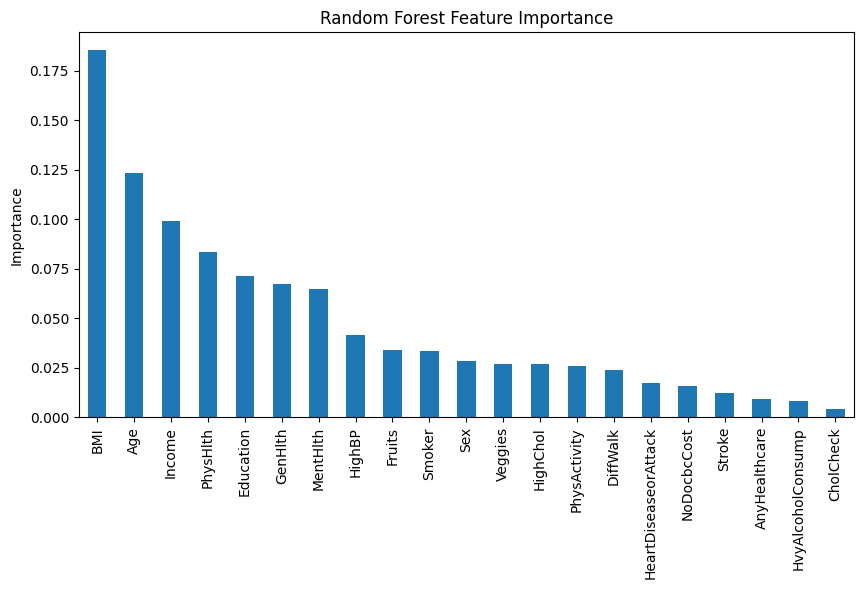

In [11]:
# Step 6: Find feature importance
importance = pd.Series(model1.feature_importances_, index=X.columns)
importance = importance.sort_values(ascending=False)
print(importance)

importance.plot(kind='bar', figsize=(10, 5))
plt.title('Random Forest Feature Importance')
plt.ylabel('Importance')
plt.show()

In [12]:
# Step 7: Select top 10 features
selected_features = importance.head(10).index
X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]
print('Selected Features:', list(selected_features))

Selected Features: ['BMI', 'Age', 'Income', 'PhysHlth', 'Education', 'GenHlth', 'MentHlth', 'HighBP', 'Fruits', 'Smoker']


In [13]:
# Step 8: Train model using selected features
model2 = RandomForestClassifier(n_estimators=50, random_state=42)
model2.fit(X_train_selected, y_train)
accuracy2 = model2.score(X_test_selected, y_test)
print('Accuracy after feature selection:', accuracy2)

Accuracy after feature selection: 0.8288986124251025


Before Feature Selection: 0.8402514979501734
After Feature Selection: 0.8288986124251025


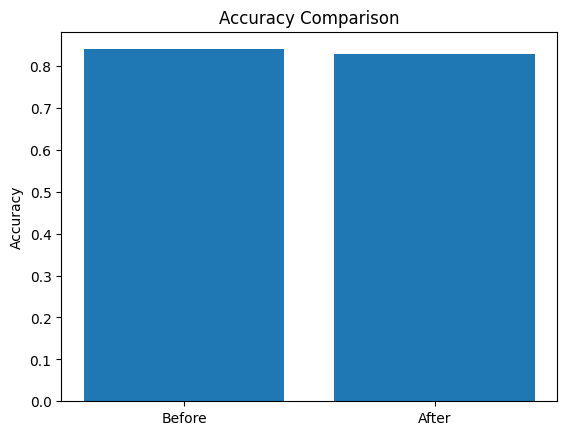

In [14]:
# Step 9: Compare model performance
print('Before Feature Selection:', accuracy1)
print('After Feature Selection:', accuracy2)

plt.bar(['Before', 'After'], [accuracy1, accuracy2])
plt.title('Accuracy Comparison')
plt.ylabel('Accuracy')
plt.show()

## Conclusion

Random Forest Feature Importance was used to select the top 10 features from the Diabetes Health Indicators dataset. Model accuracy before and after feature selection was compared.